In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd
from numpy import quantile
import cmasher as cm


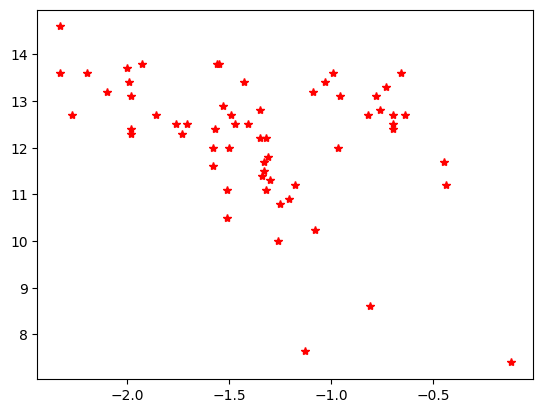

In [3]:
df = pd.read_csv('Krause21.csv')

Metallicity = df['FeH']
Age = df['Age']     # Age given in Myrs
Mstar = df['Mstar'] # Mass given in 10^5 solar masses
R_half = df['rh']   # Half mass radius for each star

plt.plot(Metallicity, Age, "r*")
plt.show()


In [69]:
# We want to compile all 4 of the data sets into one, but we only want to accept ID's that all four datasets have.
# The tricky thing is that the four datasets have different ways of displaying the ID's so each paragraph must format the ID's
# to be identical first. Then we find the intersection between the four sets.

krause21 = pd.read_csv('Krause21.csv')      # Read Csv File
data_id_krause = krause21["Object"]         # Only take "object" column (IDs)
# print(list(data_id_krause))
data_id_krause_fix = []                     # Here I'm creating an empty list, this will be the list of formatted IDs
for i in list(data_id_krause):              # for each ID tag
    if i[0:3] == "NGC":                     # if the first three letters are NGC
        j = i[3:]                           # then note the rest of the code
        # print(j)
        data_id_krause_fix.append(j)        # and add it to the empty list from above
    else:
        # print(i)
        data_id_krause_fix.append(i)
data_id_krause_fix = set(data_id_krause_fix)    # we want to turn the list into a set because a set will not care about order
print("krause: ", data_id_krause_fix)


harris1 = pd.read_csv('HarrisPartI.csv')        # Read Csv File 
data_id_harris1 = harris1["ID"]                 # Only take ID's
# print(list(data_id_harris1))
data_id_harris1_fix = []
for i in list(data_id_harris1):
    if i[0:3] == "NGC":                         # if the first letters are NGC
        j = i.split(" ")                        # split the string into 2 parts
        # print(j[1])
        data_id_harris1_fix.append(j[1])        # then add the second half
    else:
        # print(i)
        data_id_harris1_fix.append(i)
data_id_harris1_fix = set(data_id_harris1_fix)
print("harris1: ", data_id_harris1_fix)

harris3 = pd.read_csv('HarrisPartIII.csv')
data_id_harris3 = harris3["ID"]
# print(list(data_id_harris3))
data_id_harris3_fix = []
for i in list(data_id_harris3):
    if i[0:3] == "NGC":
        f = i.split(" ")
        # print(f[1])
        data_id_harris3_fix.append(f[1])
    else:
        # print(i)
        data_id_harris3_fix.append(i)
data_id_harris3_fix = set(data_id_harris3_fix)
print("harris3: ", data_id_harris3_fix)

vandenberg = pd.read_csv("vandenBerg_table2.csv")
data_id_vandenberg = vandenberg["#NGC"]
# print(list(data_id_vandenberg))
data_id_vandenberg_fix = set(data_id_vandenberg)
print("vandenberg: ", data_id_vandenberg_fix)

len(data_id_harris3_fix & data_id_harris1_fix & data_id_vandenberg_fix & data_id_krause_fix)
print(list(data_id_harris3_fix & data_id_harris1_fix & data_id_vandenberg_fix & data_id_krause_fix))



krause:  {'6101', '6535', '6838', '6779', '6366', '6218', '5272', '5904', '6681', '7099', '4833', '6121', '6981', '6254', 'Palomar12', '6388', '6637', '6934', '5897', '6304', '5286', '6144', '6652', '288', '5986', '6715', '6752', '5024', '1904', '6352', '104', '6139', '6717', '6441', '6205', '6541', '3201', '5466', '1261', '5927', '6093', '6397', '6624', '6656', '6723', '5053', '6171', '2298', '362', '1851', '6341', '6809', '2808', '6362', 'Ruprecht106', 'Terzan7', '7089', '6496', '4590', '6584', '7078'}
harris1:  {'6864', '6838', 'Pal 14', 'Pal 5', '6366', '7006', '4147', 'Pal 15', '6626', 'Pal 2', 'HP 1', 'Ton 2', 'Terzan 8', '6637', 'Djorg 1', '6144', '6652', '5824', '288', 'Liller 1', 'Pyxis', '6342', '6642', '104', '6284', 'Ko 1', '6712', '6441', '6681', '3201', '5466', '5927', '6380', '6397', '6624', 'Terzan 12', '6453', 'Arp 2', '2MS-GC02', '2298', 'Pal 11', '6809', 'IC 4499', '6256', '6528', '7089', '6266', 'Pal 1', '7078', '6535', 'Ko 2', '6218', 'ESO-SC06', '5904', '4833', '6

In [70]:
harris1 = pd.read_csv('HarrisPartI.csv')
harris1["ID"] = harris1["ID"].str.replace(" ", "")
# print(harris1)

harris3 = pd.read_csv('HarrisPartIII.csv')
harris3["ID"] = harris3["ID"].str.replace(" ", "")
# print(harris3)

vandenberg = pd.read_csv("vandenBerg_table2.csv")
vandenberg['#NGC'] = 'NGC' + vandenberg['#NGC'].astype(str)
# print(vandenberg)

krause21 = pd.read_csv('Krause21.csv')      # Read Csv File
data_id_krause = krause21["Object"]

merge_1 = pd.merge(harris1, harris3,  on='ID')
# print(merge_1)
merge_2 = pd.merge(merge_1, krause21, left_on='ID', right_on='Object')
# print(merge_2)
merge_3 = pd.merge(merge_2, vandenberg, left_on='ID', right_on='#NGC')
print(merge_3)
merge_final = merge_3.drop(columns=["#NGC", "Object"])
merge_final.to_csv("GC_Merged_Table.csv", index = False)

         ID  Name_x           RA          DEC       L      B  R_Sun  R_gc  \
0    NGC104  47 Tuc  00:24:05.67  -72:04:52.6  305.89 -44.89    4.5   7.4   
1    NGC288     NaN  00:52:45.24  -26:34:57.4  152.30 -89.38    8.9  12.0   
2    NGC362     NaN  01:03:14.26  -70:50:55.6  301.53 -46.25    8.6   9.4   
3   NGC1261     NaN  03:12:16.21  -55:12:58.4  270.54 -52.12   16.3  18.1   
4   NGC1851     NaN  05:14:06.76  -40:02:47.6  244.51 -35.03   12.1  16.6   
5   NGC2808     NaN  09:12:03.10  -64:51:48.6  282.19 -11.25    9.6  11.1   
6   NGC3201     NaN  10:17:36.82  -46:24:44.9  277.23   8.64    4.9   8.8   
7   NGC4590    M 68  12:39:27.98  -26:44:38.6  299.63  36.05   10.3  10.2   
8   NGC4833     NaN  12:59:33.92  -70:52:35.4  303.60  -8.02    6.6   7.0   
9   NGC5024    M 53  13:12:55.25  +18:10:05.4  332.96  79.76   17.9  18.4   
10  NGC5053     NaN  13:16:27.09  +17:42:00.9  335.70  78.95   17.4  17.8   
11  NGC5272     M 3  13:42:11.62  +28:22:38.2   42.22  78.71   10.2  12.0   

         ID Name_x           RA          DEC       L      B  R_Sun  R_gc  \
1    NGC288    NaN  00:52:45.24  -26:34:57.4  152.30 -89.38    8.9  12.0   
3   NGC1261    NaN  03:12:16.21  -55:12:58.4  270.54 -52.12   16.3  18.1   
4   NGC1851    NaN  05:14:06.76  -40:02:47.6  244.51 -35.03   12.1  16.6   
5   NGC2808    NaN  09:12:03.10  -64:51:48.6  282.19 -11.25    9.6  11.1   
7   NGC4590   M 68  12:39:27.98  -26:44:38.6  299.63  36.05   10.3  10.2   
9   NGC5024   M 53  13:12:55.25  +18:10:05.4  332.96  79.76   17.9  18.4   
10  NGC5053    NaN  13:16:27.09  +17:42:00.9  335.70  78.95   17.4  17.8   
11  NGC5272    M 3  13:42:11.62  +28:22:38.2   42.22  78.71   10.2  12.0   
13  NGC5466    NaN  14:05:27.29  +28:32:04.0   42.15  73.59   16.0  16.3   
18  NGC6101    NaN  16:25:48.12  -72:12:07.9  317.74 -15.82   15.4  11.2   
39  NGC6715   M 54  18:55:03.33  -30:28:47.5    5.61 -14.09   26.5  18.9   
46  NGC6934    NaN  20:34:11.37  +07:24:16.1   52.10 -18.89   15.6  12.8   
47  NGC6981 

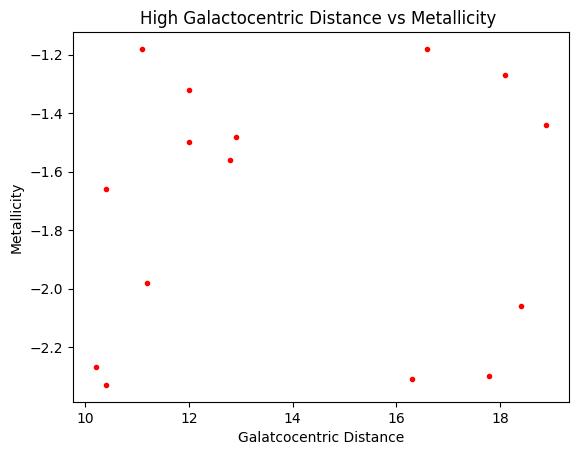

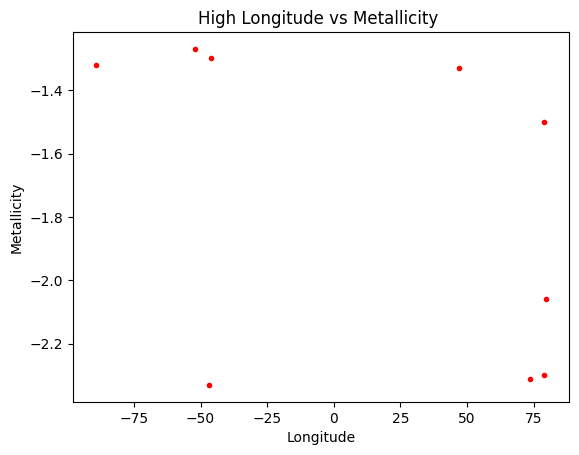

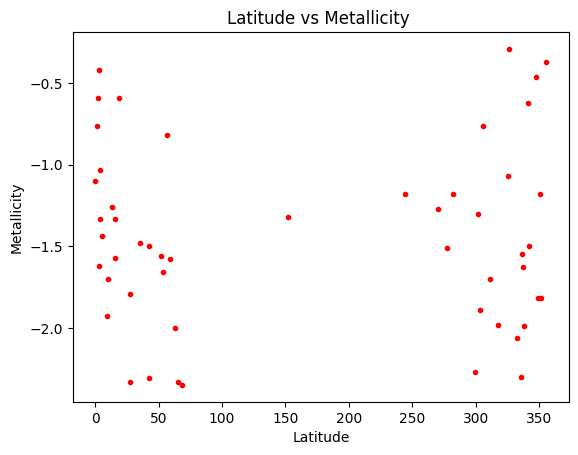

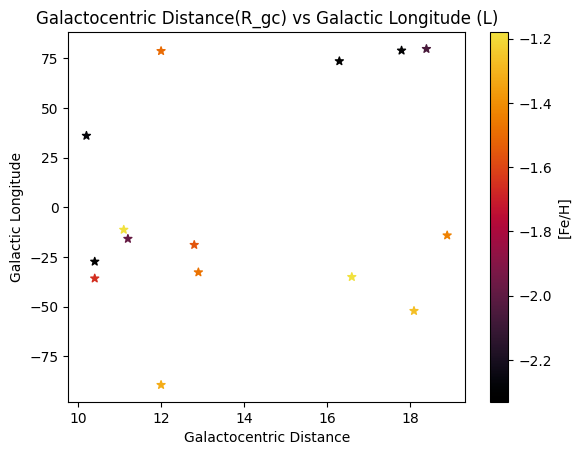

In [4]:
# Now I would like to inspect the correlation between high ecentricity orbits and metallicity.

mdf = pd.read_csv('GC_Merged_Table.csv')
R_gc = mdf['R_gc']
Metallicity = mdf['FeH_y']
G_Longitude = mdf['B']

High_R_gc = mdf[mdf['R_gc'] > 10]
print(High_R_gc)
High_Long = mdf[(mdf['B'] > 45) | (mdf['B'] < -45)]
print(High_Long)

plt.plot(High_R_gc['R_gc'], High_R_gc['FeH_y'], "r.")
plt.xlabel("Galatcocentric Distance")
plt.ylabel("Metallicity")
plt.title("High Galactocentric Distance vs Metallicity ")
plt.show()

plt.plot(High_Long['B'], High_Long['FeH_y'], "r.")
plt.xlabel("Longitude")
plt.ylabel("Metallicity")
plt.title("High Longitude vs Metallicity ")
plt.show()

plt.plot(mdf['L'], mdf['FeH_y'], "r.")
plt.xlabel("Latitude")
plt.ylabel("Metallicity")
plt.title("Latitude vs Metallicity ")
plt.show()

plt.scatter(High_R_gc['R_gc'], High_R_gc['B'], c=High_R_gc['FeH_y'], cmap=cm.ember, marker='*')
plt.colorbar(label='[Fe/H]')
plt.xlabel("Galactocentric Distance")
plt.ylabel("Galactic Longitude")
plt.title("Galactocentric Distance(R_gc) vs Galactic Longitude (L)")
plt.show()


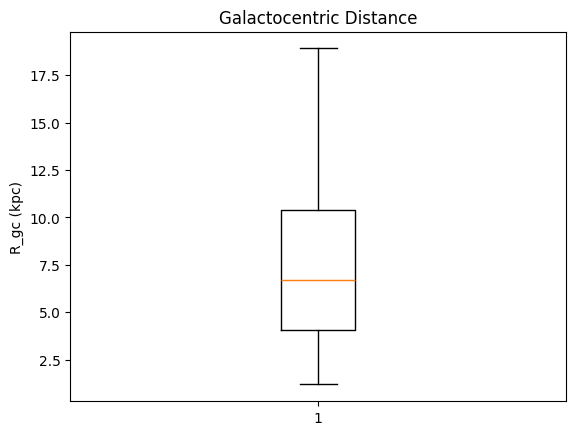

Mean R_gc = 7.723529411764705
Q1= [4.05]
Q3= [10.4]
IQR = 6.3500000000000005
outlier cutoff = [-5.475] [19.925]
max= R_gc    18.9
dtype: float64
min= R_gc    1.2
dtype: float64


In [72]:
# Galactocentric Distance Data Analysis

R_gc = pd.DataFrame(R_gc)   # This makes the column of R_gc easier to put into a box plot 
plt.boxplot(R_gc)           # also this tiny section of code is stolen from matildas section tysm <3
plt.title('Galactocentric Distance')
plt.ylabel('R_gc (kpc)')
plt.show()

print('Mean R_gc =', np.mean(R_gc))
Q1_R_gc = quantile(R_gc, [0.25]) # define 1st quartile of metallicity
Q3_R_gc = quantile(R_gc,[0.75])  # define 3rd quartile of metallicity
iqr_R_gc = stats.iqr(R_gc)       # finds IQR (could also be done by Q3-Q1)
print('Q1=',Q1_R_gc)
print('Q3=',Q3_R_gc)
print('IQR =', iqr_R_gc)
print('outlier cutoff =', Q1_R_gc-1.5*iqr_R_gc, Q3_R_gc+1.5*iqr_R_gc) # Finds the cutoff below and above which values are considered outliers
print('max=', R_gc.max())        # Finds maximum value in the metallicity column
print('min=', R_gc.min())        # Finds the minimum value in the metallicity column

# No outliers Found


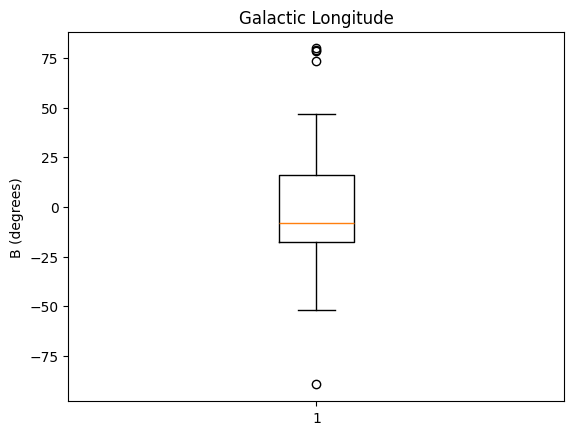

Mean G_longitude = -0.6409803921568631
Q1= [-17.435]
Q3= [15.835]
IQR = 33.27
outlier cutoff = [-67.34] [65.74]
max= B    79.76
dtype: float64
min= B   -89.38
dtype: float64


In [73]:
# Galactic Longitude Analysis

G_Longitude = pd.DataFrame(G_Longitude)   # This makes the column of R_gc easier to put into a box plot 
plt.boxplot(G_Longitude)           # also this tiny section of code is stolen from matildas section tysm <3
plt.title('Galactic Longitude')
plt.ylabel('B (degrees)')
plt.show()

print('Mean G_longitude =', np.mean(G_Longitude))
Q1_G_longitude = quantile(G_Longitude, [0.25]) # define 1st quartile of metallicity
Q3_G_longitude = quantile(G_Longitude,[0.75])  # define 3rd quartile of metallicity
iqr_G_longitude = stats.iqr(G_Longitude)       # finds IQR (could also be done by Q3-Q1)
print('Q1=',Q1_G_longitude)
print('Q3=',Q3_G_longitude)
print('IQR =', iqr_G_longitude)
print('outlier cutoff =', Q1_G_longitude-1.5*iqr_G_longitude, Q3_G_longitude+1.5*iqr_G_longitude) # Finds the cutoff below and above which values are considered outliers
print('max=', G_Longitude.max())        # Finds maximum value in the metallicity column
print('min=', G_Longitude.min())        # Finds the minimum value in the metallicity column

# No outliers Found


<function matplotlib.pyplot.show(close=None, block=None)>

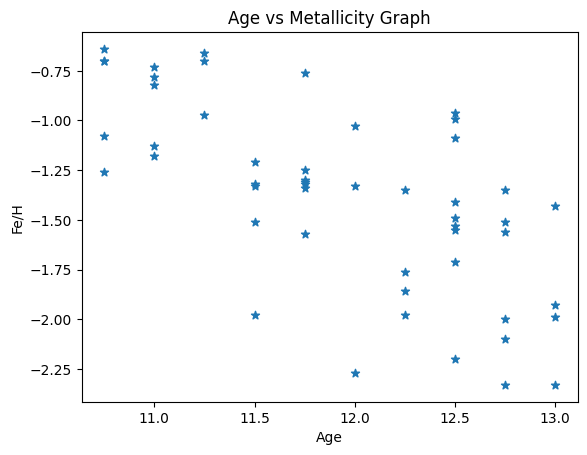

In [ ]:
# Age Metallicity Relation

plt.scatter(mdf['Age_y'], mdf['FeH_x'], marker='*')
plt.xlabel('Age')
plt.ylabel('Fe/H')
plt.title('Age vs Metallicity Graph')
plt.show

         ID Name_x           RA          DEC       L      B  R_Sun  R_gc  \
6   NGC3201    NaN  10:17:36.82  -46:24:44.9  277.23   8.64    4.9   8.8   
8   NGC4833    NaN  12:59:33.92  -70:52:35.4  303.60  -8.02    6.6   7.0   
12  NGC5286    NaN  13:46:26.81  -51:22:27.3  311.61  10.57   11.7   8.9   
15  NGC5927    NaN  15:28:00.69  -50:40:22.9  326.60   4.86    7.7   4.6   
16  NGC5986    NaN  15:46:03.00  -37:47:11.1  337.02  13.27   10.4   4.8   
17  NGC6121    M 4  16:23:35.22  -26:31:32.7  350.97  15.97    2.2   5.9   
19  NGC6144    NaN  16:27:13.86  -26:01:24.6  351.93  15.70    8.9   2.7   
20  NGC6171  M 107  16:32:31.86  -13:03:13.6    3.37  23.01    6.4   3.3   
22  NGC6218   M 12  16:47:14.18  -01:56:54.7   15.72  26.31    4.8   4.5   
23  NGC6254   M 10  16:57:09.05  -04:06:01.1   15.14  23.08    4.4   4.6   
24  NGC6304    NaN  17:14:32.25  -29:27:43.3  355.83   5.38    5.9   2.3   
26  NGC6352    NaN  17:25:29.11  -48:25:19.8  341.42  -7.17    5.6   3.3   
28  NGC6362 

<function matplotlib.pyplot.show(close=None, block=None)>

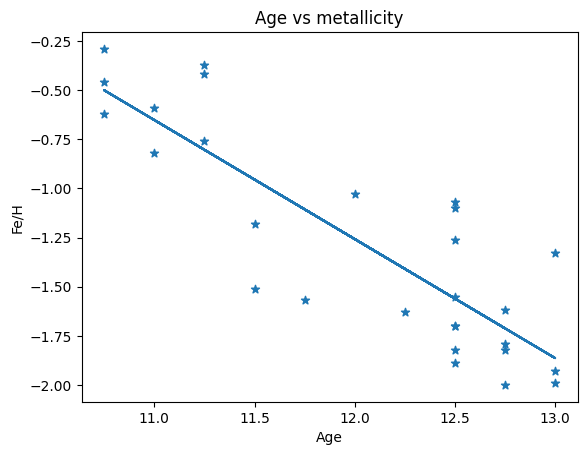

In [ ]:
# I would like to fit a line of best fit amongst GCS who are not accreted.

non_accreted = mdf[(mdf['R_gc'] < 5) | ((mdf['Z'] > -3) & (mdf['Z'] < 3) & (mdf['R_gc'] > 5) & (mdf['R_gc'] < 11))]
print(non_accreted)
m, b = np.polyfit(non_accreted['Age_y'], non_accreted['FeH_y'], 1)
line_metal = m*non_accreted['Age_y'] + b
plt.scatter(non_accreted['Age_y'], non_accreted['FeH_y'], marker="*")
plt.plot(non_accreted['Age_y'], line_metal)
plt.xlabel('Age')
plt.ylabel('Fe/H')
plt.title('Age vs metallicity')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

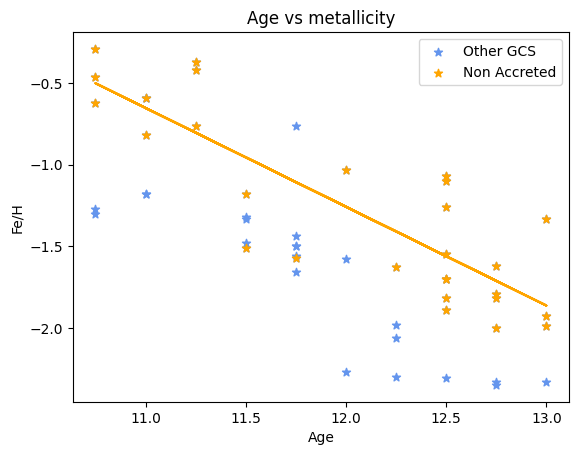

In [ ]:
# Here I am forming a line of best fit amonogst globular clusters that are close to the center of the Galaxy
# These are likely not accreted.

non_accreted = mdf[(mdf['R_gc'] < 5) | ((mdf['Z'] > -3) & (mdf['Z'] < 3) & (mdf['R_gc'] > 5) & (mdf['R_gc'] < 11))]
line_non_accreted = m*non_accreted['Age_y'] + b
plt.scatter(mdf['Age_y'], mdf['FeH_y'], marker = '*', label = "Other GCS", color = "cornflowerblue")
plt.scatter(non_accreted['Age_y'], non_accreted['FeH_y'], color="orange", marker="*", label = "Non Accreted")
plt.plot(non_accreted['Age_y'], line_metal, color = 'orange')
plt.legend()
plt.xlabel('Age')
plt.ylabel('Fe/H')
plt.title('Age vs metallicity')
plt.show

In [ ]:
# Here I am trying to find the distance between each globular cluster and the line, in order to sort them from most likely to be accreted to least likely.

possible_accreted = mdf[~mdf["ID"].isin(non_accreted["ID"])]
possible_accreted["distance"] = possible_accreted["FeH_y"] - (m*possible_accreted["Age_y"]+b)
print(possible_accreted)

distance_order["distance"] = possible_accreted["distance"].abs()
distance_order = distance_order.sort_values(by='distance', ascending=False)
print(distance_order)
print(distance_order["ID"])     # This list is in descending order of most to least likely accreted GCS

         ID  Name_x           RA          DEC       L      B  R_Sun  R_gc  \
0    NGC104  47 Tuc  00:24:05.67  -72:04:52.6  305.89 -44.89    4.5   7.4   
1    NGC288     NaN  00:52:45.24  -26:34:57.4  152.30 -89.38    8.9  12.0   
2    NGC362     NaN  01:03:14.26  -70:50:55.6  301.53 -46.25    8.6   9.4   
3   NGC1261     NaN  03:12:16.21  -55:12:58.4  270.54 -52.12   16.3  18.1   
4   NGC1851     NaN  05:14:06.76  -40:02:47.6  244.51 -35.03   12.1  16.6   
5   NGC2808     NaN  09:12:03.10  -64:51:48.6  282.19 -11.25    9.6  11.1   
7   NGC4590    M 68  12:39:27.98  -26:44:38.6  299.63  36.05   10.3  10.2   
9   NGC5024    M 53  13:12:55.25  +18:10:05.4  332.96  79.76   17.9  18.4   
10  NGC5053     NaN  13:16:27.09  +17:42:00.9  335.70  78.95   17.4  17.8   
11  NGC5272     M 3  13:42:11.62  +28:22:38.2   42.22  78.71   10.2  12.0   
13  NGC5466     NaN  14:05:27.29  +28:32:04.0   42.15  73.59   16.0  16.3   
14  NGC5904     M 5  15:18:33.22  +02:04:51.7    3.86  46.80    7.5   6.2   

         ID  Name_x           RA          DEC       L      B  R_Sun  R_gc  \
0    NGC104  47 Tuc  00:24:05.67  -72:04:52.6  305.89 -44.89    4.5   7.4   
1    NGC288     NaN  00:52:45.24  -26:34:57.4  152.30 -89.38    8.9  12.0   
2    NGC362     NaN  01:03:14.26  -70:50:55.6  301.53 -46.25    8.6   9.4   
3   NGC1261     NaN  03:12:16.21  -55:12:58.4  270.54 -52.12   16.3  18.1   
4   NGC1851     NaN  05:14:06.76  -40:02:47.6  244.51 -35.03   12.1  16.6   
5   NGC2808     NaN  09:12:03.10  -64:51:48.6  282.19 -11.25    9.6  11.1   
7   NGC4590    M 68  12:39:27.98  -26:44:38.6  299.63  36.05   10.3  10.2   
9   NGC5024    M 53  13:12:55.25  +18:10:05.4  332.96  79.76   17.9  18.4   
10  NGC5053     NaN  13:16:27.09  +17:42:00.9  335.70  78.95   17.4  17.8   
11  NGC5272     M 3  13:42:11.62  +28:22:38.2   42.22  78.71   10.2  12.0   
13  NGC5466     NaN  14:05:27.29  +28:32:04.0   42.15  73.59   16.0  16.3   
14  NGC5904     M 5  15:18:33.22  +02:04:51.7    3.86  46.80    7.5   6.2   

<function matplotlib.pyplot.show(close=None, block=None)>

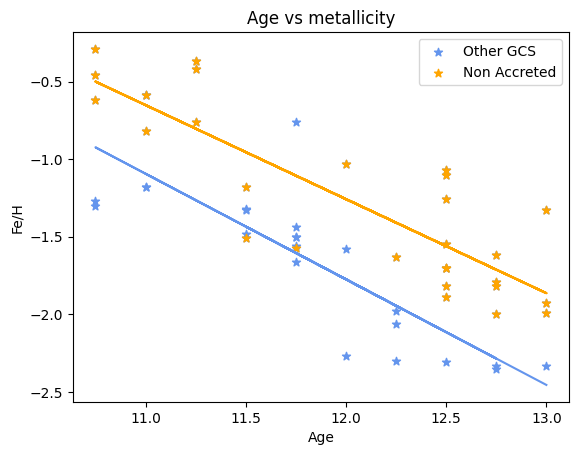

In [ ]:
# Here I am trying to fit another line to the Globular clusters that are not apart of non-accreted set.
# It is clear that they follow another relation.

non_accreted = mdf[(mdf['R_gc'] < 5) | ((mdf['Z'] > -3) & (mdf['Z'] < 3) & (mdf['R_gc'] > 5) & (mdf['R_gc'] < 11))]
line_metal = m*non_accreted['Age_y'] + b
possible_accreted = mdf[~mdf["ID"].isin(non_accreted["ID"])]
n, v = np.polyfit(possible_accreted['Age_y'], possible_accreted['FeH_y'], 1)
line_possible_accreted = n*possible_accreted['Age_y'] + v
print(possible_accreted)
plt.scatter(mdf['Age_y'], mdf['FeH_y'], marker = '*', label = "Other GCS", color = "cornflowerblue")
plt.scatter(non_accreted['Age_y'], non_accreted['FeH_y'], color="orange", marker="*", label = "Non Accreted")
plt.plot(non_accreted['Age_y'], line_metal, color = 'orange')
plt.plot(possible_accreted['Age_y'], line_possible_accreted, color = 'cornflowerblue')
plt.legend()
plt.xlabel('Age')
plt.ylabel('Fe/H')
plt.title('Age vs metallicity')
plt.show